# External Validation — TCGA-trained model tested on GSE37745 (Uppsala, Sweden)



## 1. Imports and Settings

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score, balanced_accuracy_score,
                             confusion_matrix, roc_curve, classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

DATA_DIR = "../data"                       # folder where the 4 CSV files are kept
OUTPUT_DIR = "../results/external_validation"
os.makedirs(OUTPUT_DIR, exist_ok=True)

PATHS = {
    "LUAD": os.path.join(DATA_DIR, "LUAD.csv"),
    "LUSC": os.path.join(DATA_DIR, "LUSC.csv"),
    "GSE_EXPR": os.path.join(DATA_DIR, "GSE37745_expression.csv"),
    "GSE_CLIN": os.path.join(DATA_DIR, "GSE37745_clinical.csv"),
}
for k, p in PATHS.items():
    print(f"{k:9s} -> {p}  {'OK' if os.path.exists(p) else 'NOT FOUND !!!'}")

N_BOOTSTRAP = 1000                   # for 95% confidence intervals on the external cohort
TCGA_TUNED_C = 6.581                 # C found by Optuna in the original TCGA pipeline

LUAD      -> .\LUAD.csv  OK
LUSC      -> .\LUSC.csv  OK
GSE_EXPR  -> .\GSE37745_expression.csv  OK
GSE_CLIN  -> .\GSE37745_clinical.csv  OK


## 2. Load TCGA (training cohort) — same rules as the original pipeline

In [2]:
def load_primary_tumor(path, label):
    expr = pd.read_csv(path, index_col=0).T          # rows = samples, columns = genes
    expr.index.name = "sampleID"
    n_before = len(expr)
    expr = expr[expr.index.str.endswith("-01")]      # Primary Tumor only
    print(f"  {label}: {n_before} raw samples -> {len(expr)} Primary Tumor samples")
    return expr.astype(np.float32), pd.Series(label, index=expr.index)

X_luad, y_luad = load_primary_tumor(PATHS["LUAD"], "LUAD")
X_lusc, y_lusc = load_primary_tumor(PATHS["LUSC"], "LUSC")
common_tcga = X_luad.columns.intersection(X_lusc.columns)
X_tcga = pd.concat([X_luad[common_tcga], X_lusc[common_tcga]], axis=0)
y_tcga = (pd.concat([y_luad, y_lusc]) == "LUSC").astype(int)

# gene names: keep only the symbol part (handles "GENE|ENTREZ" style if present)
X_tcga.columns = [str(c).split("|")[0].upper() for c in X_tcga.columns]
X_tcga = X_tcga.loc[:, ~X_tcga.columns.duplicated()]

print(f"\nTCGA: {X_tcga.shape[0]} samples, {X_tcga.shape[1]} genes | "
      f"LUAD={int((y_tcga==0).sum())}, LUSC={int((y_tcga==1).sum())}")

  LUAD: 576 raw samples -> 515 Primary Tumor samples
  LUSC: 553 raw samples -> 502 Primary Tumor samples

TCGA: 1017 samples, 20502 genes | LUAD=515, LUSC=502


## 3. Load GSE37745 (external test cohort)

In [3]:
gse_expr = pd.read_csv(PATHS["GSE_EXPR"], index_col=0).T     # rows = samples, columns = genes
gse_expr.columns = [str(c).upper() for c in gse_expr.columns]
gse_expr = gse_expr.loc[:, ~gse_expr.columns.duplicated()]
gse_clin = pd.read_csv(PATHS["GSE_CLIN"], index_col=0)

gse_clin = gse_clin[gse_clin["histology"].isin(["LUAD", "LUSC"])]
X_gse = gse_expr.loc[gse_clin.index].astype(np.float32)
y_gse = (gse_clin["histology"] == "LUSC").astype(int)

print(f"GSE37745: {X_gse.shape[0]} samples, {X_gse.shape[1]} genes | "
      f"LUAD={int((y_gse==0).sum())}, LUSC={int((y_gse==1).sum())}")

GSE37745: 172 samples, 21653 genes | LUAD=106, LUSC=66


## 4. Harmonise the two cohorts



In [4]:
common_genes = sorted(set(X_tcga.columns) & set(X_gse.columns))
Xt = X_tcga[common_genes]
Xg = X_gse[common_genes]

ok = (Xt.std(axis=0) > 1e-6) & (Xg.std(axis=0) > 1e-6)
common_genes = [g for g in common_genes if ok[g]]
Xt, Xg = Xt[common_genes], Xg[common_genes]
print(f"Genes in TCGA: {X_tcga.shape[1]} | in GSE37745: {X_gse.shape[1]} | "
      f"common & non-constant: {len(common_genes)}")

def zscore_within_cohort(df):
    return (df - df.mean(axis=0)) / (df.std(axis=0) + 1e-8)

Xt_z = zscore_within_cohort(Xt).values
Xg_z = zscore_within_cohort(Xg).values
yt = y_tcga.values
yg = y_gse.values

pd.Series(common_genes).to_csv(f"{OUTPUT_DIR}/common_genes.csv", index=False, header=["gene"])

Genes in TCGA: 20502 | in GSE37745: 21653 | common & non-constant: 16315


### 4.1 Quick visual check — do the cohorts overlap after harmonisation?


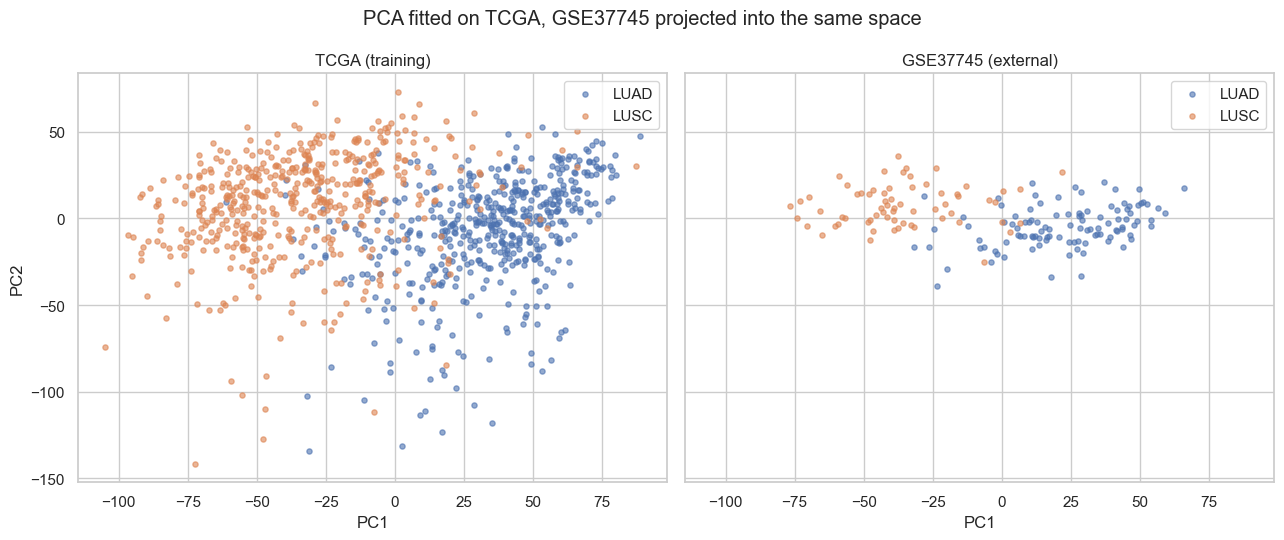

In [5]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xt_z)
pt, pg = pca.transform(Xt_z), pca.transform(Xg_z)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, P, yy, name in [(axes[0], pt, yt, "TCGA (training)"), (axes[1], pg, yg, "GSE37745 (external)")]:
    ax.scatter(P[yy==0,0], P[yy==0,1], s=14, alpha=.6, c="#4C72B0", label="LUAD")
    ax.scatter(P[yy==1,0], P[yy==1,1], s=14, alpha=.6, c="#DD8452", label="LUSC")
    ax.set_title(name); ax.set_xlabel("PC1"); ax.legend()
axes[0].set_ylabel("PC2")
plt.suptitle("PCA fitted on TCGA, GSE37745 projected into the same space")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/pca_tcga_vs_gse.png", dpi=150); plt.show()

## 5. Train the model on TCGA only



In [6]:
C_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 6.581, 10]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(LogisticRegression(max_iter=5000, class_weight="balanced"),
                    {"C": C_GRID}, scoring="roc_auc", cv=cv, n_jobs=-1)
grid.fit(Xt_z, yt)
BEST_C = grid.best_params_["C"]
print("CV AUC on TCGA for each C:")
for c, s in zip(C_GRID, grid.cv_results_["mean_test_score"]):
    print(f"   C={c:<7} AUC={s:.4f}{'   <-- best' if c == BEST_C else ''}")

# internal (TCGA) reference performance on the SAME common-gene, z-scored feature set
int_proba = cross_val_predict(LogisticRegression(C=BEST_C, max_iter=5000, class_weight="balanced"),
                              Xt_z, yt, cv=cv, method="predict_proba")[:, 1]
print(f"\nInternal TCGA 5-fold CV (common genes): AUC={roc_auc_score(yt, int_proba):.4f}, "
      f"Acc={accuracy_score(yt, int_proba>=.5)*100:.2f}%")

final_model = LogisticRegression(C=BEST_C, max_iter=5000, class_weight="balanced").fit(Xt_z, yt)

CV AUC on TCGA for each C:
   C=0.001   AUC=0.9889
   C=0.003   AUC=0.9889
   C=0.01    AUC=0.9889   <-- best
   C=0.03    AUC=0.9888
   C=0.1     AUC=0.9887
   C=0.3     AUC=0.9886
   C=1       AUC=0.9888
   C=3       AUC=0.9885
   C=6.581   AUC=0.9885
   C=10      AUC=0.9884

Internal TCGA 5-fold CV (common genes): AUC=0.9888, Acc=96.17%


## 6. External test on GSE37745 (model is frozen — no retraining)

In [7]:
def all_metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"AUC": roc_auc_score(y_true, proba),
            "Accuracy": accuracy_score(y_true, pred),
            "Balanced_Accuracy": balanced_accuracy_score(y_true, pred),
            "F1_LUSC": f1_score(y_true, pred),
            "Sensitivity_LUSC": tp / (tp + fn),
            "Specificity_LUAD": tn / (tn + fp)}

def bootstrap_ci(y_true, proba, n=N_BOOTSTRAP, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    rows = []
    for _ in range(n):
        idx = rng.randint(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        rows.append(all_metrics(y_true[idx], proba[idx]))
    b = pd.DataFrame(rows)
    return b.quantile(0.025), b.quantile(0.975)

ext_proba = final_model.predict_proba(Xg_z)[:, 1]
ext_pred = (ext_proba >= 0.5).astype(int)
ext = all_metrics(yg, ext_proba)
lo, hi = bootstrap_ci(yg, ext_proba)

print("=" * 62)
print(f" EXTERNAL VALIDATION — GSE37745 (n={len(yg)}), model trained on TCGA only")
print("=" * 62)
for k, v in ext.items():
    print(f"  {k:18s}: {v:.4f}   (95% CI {lo[k]:.4f} – {hi[k]:.4f})")
print()
print(classification_report(yg, ext_pred, target_names=["LUAD", "LUSC"], digits=4))

 EXTERNAL VALIDATION — GSE37745 (n=172), model trained on TCGA only
  AUC               : 0.9911   (95% CI 0.9789 – 0.9993)
  Accuracy          : 0.9535   (95% CI 0.9186 – 0.9826)
  Balanced_Accuracy : 0.9594   (95% CI 0.9291 – 0.9830)
  F1_LUSC           : 0.9420   (95% CI 0.8939 – 0.9759)
  Sensitivity_LUSC  : 0.9848   (95% CI 0.9492 – 1.0000)
  Specificity_LUAD  : 0.9340   (95% CI 0.8830 – 0.9741)

              precision    recall  f1-score   support

        LUAD     0.9900    0.9340    0.9612       106
        LUSC     0.9028    0.9848    0.9420        66

    accuracy                         0.9535       172
   macro avg     0.9464    0.9594    0.9516       172
weighted avg     0.9565    0.9535    0.9538       172



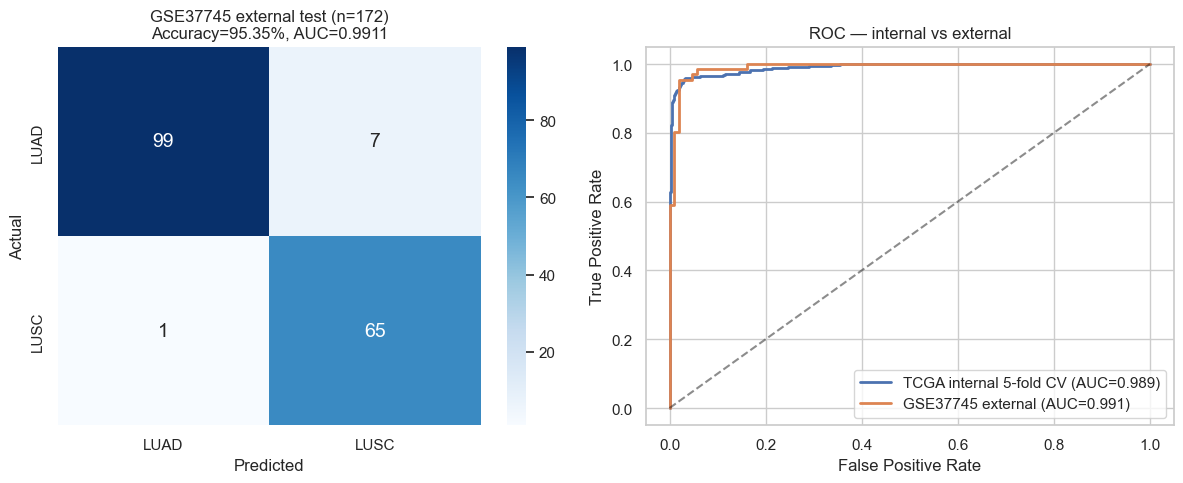

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(yg, ext_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], annot_kws={"size": 14},
            xticklabels=["LUAD", "LUSC"], yticklabels=["LUAD", "LUSC"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title(f"GSE37745 external test (n={len(yg)})\n"
                  f"Accuracy={ext['Accuracy']*100:.2f}%, AUC={ext['AUC']:.4f}")

fpr_i, tpr_i, _ = roc_curve(yt, int_proba)
fpr_e, tpr_e, _ = roc_curve(yg, ext_proba)
axes[1].plot(fpr_i, tpr_i, lw=2, label=f"TCGA internal 5-fold CV (AUC={roc_auc_score(yt, int_proba):.3f})")
axes[1].plot(fpr_e, tpr_e, lw=2, label=f"GSE37745 external (AUC={ext['AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.5)
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC — internal vs external"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/external_cm_roc.png", dpi=150); plt.show()

## 7. Ablation — why per-cohort normalisation is needed


In [9]:
raw_model = LogisticRegression(C=BEST_C, max_iter=5000, class_weight="balanced").fit(Xt.values, yt)
raw_proba = raw_model.predict_proba(Xg.values)[:, 1]
raw = all_metrics(yg, raw_proba)
print("Without per-cohort normalisation (raw values):")
for k, v in raw.items():
    print(f"  {k:18s}: {v:.4f}")

Without per-cohort normalisation (raw values):
  AUC               : 0.9896
  Accuracy          : 0.9651
  Balanced_Accuracy : 0.9631
  F1_LUSC           : 0.9545
  Sensitivity_LUSC  : 0.9545
  Specificity_LUAD  : 0.9717


## 8. Summary table for the paper

In [10]:
internal = all_metrics(yt, int_proba)
summary = pd.DataFrame({
    "TCGA internal (5-fold CV, common genes)": internal,
    "GSE37745 external (frozen model)": ext,
    "GSE37745 external — 95% CI low": lo,
    "GSE37745 external — 95% CI high": hi,
    "GSE37745 external — no normalisation (ablation)": raw,
}).T.round(4)
summary.insert(0, "n", [len(yt), len(yg), len(yg), len(yg), len(yg)])
print(summary.to_string())

summary.to_csv(f"{OUTPUT_DIR}/external_validation_summary.csv")
pd.DataFrame({"sampleID": X_gse.index, "true_LUSC": yg, "proba_LUSC": ext_proba, "pred_LUSC": ext_pred}) \
  .to_csv(f"{OUTPUT_DIR}/gse37745_predictions.csv", index=False)
with open(f"{OUTPUT_DIR}/run_info.json", "w") as f:
    json.dump({"best_C": BEST_C, "n_common_genes": len(common_genes),
               "n_tcga": int(len(yt)), "n_gse": int(len(yg))}, f, indent=2)
print(f"\nSaved everything to: {OUTPUT_DIR}/")

                                                    n     AUC  Accuracy  Balanced_Accuracy  F1_LUSC  Sensitivity_LUSC  Specificity_LUAD
TCGA internal (5-fold CV, common genes)          1017  0.9888    0.9617             0.9615   0.9606            0.9462            0.9767
GSE37745 external (frozen model)                  172  0.9911    0.9535             0.9594   0.9420            0.9848            0.9340
GSE37745 external — 95% CI low                    172  0.9789    0.9186             0.9291   0.8939            0.9492            0.8830
GSE37745 external — 95% CI high                   172  0.9993    0.9826             0.9830   0.9759            1.0000            0.9741
GSE37745 external — no normalisation (ablation)   172  0.9896    0.9651             0.9631   0.9545            0.9545            0.9717

Saved everything to: results_external_validation/
